# Survey comparison: target audience versus all eligible respondents

This notebook describes **all structured substantive questions**, preserving the original German question and answer labels. The target audience is defined by **Q25 = 4**, not by an independently sampled population. The comparison is **target versus ALL**, including target respondents in ALL; it is not target versus the remainder.

## Methodology
- Include only `completed = "1"` and nonempty processing consent (the **first Q1 checkbox**). Optional quotation consent is not a participation requirement. `terminated` is not a filter.
- Strip surrounding whitespace and convert blanks to null. Use question-wise available responses, not a complete-case subset across the survey.
- Single-choice and rating denominators: nonempty responses to that item. Checkbox denominators: respondents with **any** nonempty option in that question; blank options then mean unselected. All-empty questions are missing, not all-negative responses.
- Percentages are conditional on the relevant answered denominator. Differences are **target percentage − overall percentage**, in percentage points (pp). Undefined percentages remain null, never zero.
- Ratings use ordered codes 1–4, higher being better. Report distributions and lower-order-statistic quartiles/median, without averaging ordinal categories. Time, experience and budget brackets remain categories, not numeric midpoints.
- Q1 appears only in the consent audit. Free-text Q9, Q12, Q18, Q21, Q23, Q29 and metadata are excluded from substantive outputs. No respondent IDs, contact details or free text are displayed.
- There are no independent-group tests, p-values or confidence intervals.

## Setup
Run from the directory containing this notebook and both CSV files. `INPUT_DIR` below is explicitly the kernel's working directory; change it if launching Jupyter elsewhere.

Install dependencies if necessary in this kernel: `%pip install polars matplotlib ipython`.


In [1]:
from pathlib import Path
import re
import textwrap
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

INPUT_DIR = Path.cwd()

def show(table):
    # Local display configuration: show every row and column, including long labels.
    with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=220, tbl_width_chars=220, float_precision=2):
        display(table)

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


## Loading and validation
The schema below records the supplied export's column names. Structural or encoding changes fail explicitly rather than silently changing the analysis. Single-choice category lists record the observed export vocabulary (not a claim that absent questionnaire choices do not exist). Checkbox options come from the full column schema, including never-selected options. All rows are checked before eligibility filtering. Validation errors intentionally omit respondent values.


In [2]:
EXPECTED_COLUMNS = ['ID', 'Date', 'Question 1 - Zustimmung - Ich habe die Informationen gelesen und willige freiwillig ein, dass LOA e.V. meine Antworten zu den genannten Zwecken verarbeitet.', 'Question 1 - Zustimmung - Ich willige zusätzlich ein, dass nicht rückführbare, anonymisierte Zitate aus meinen Antworten verwendet werden. Diese Einwilligung ist freiwillig und keine Voraussetzung für die Teilnahme.', 'Question 2 - Welchem Geschlecht ordnest du dich zu?', 'Question 3 - In welchem Bundesland arbeitest du?', 'Question 4 - Wie viele Berufsjahre arbeitest du bereits?', 'Question 5 - Zu welcher Gruppe ordnest du dich zu?', 'Question 6 - Welche finanziellen Mittel stehen dir aktuell für Fort- und Weiterbildungen zur Verfügung? - Keine', 'Question 6 - Welche finanziellen Mittel stehen dir aktuell für Fort- und Weiterbildungen zur Verfügung? - Arbeitgeber', 'Question 6 - Welche finanziellen Mittel stehen dir aktuell für Fort- und Weiterbildungen zur Verfügung? - Projekt', 'Question 6 - Welche finanziellen Mittel stehen dir aktuell für Fort- und Weiterbildungen zur Verfügung? - Bildungsgutscheine', 'Question 6 - Welche finanziellen Mittel stehen dir aktuell für Fort- und Weiterbildungen zur Verfügung? - Förderprogramme', 'Question 6 - Welche finanziellen Mittel stehen dir aktuell für Fort- und Weiterbildungen zur Verfügung? - Persönliche Investments', 'Question 7 - Wie hoch waren diese finanziellen Mittel in den letzten 12 Monaten?', 'Question 8 - Welche Förderprogramme? - Bildungsurlaub', 'Question 8 - Welche Förderprogramme? - Bildungsgutschein / Bildungsscheck', 'Question 8 - Welche Förderprogramme? - KOMPASS', 'Question 8 - Welche Förderprogramme? - Projektförderung', 'Question 8 - Welche Förderprogramme? - Andere...', 'Question 9 - Andere Fördermittel', 'Question 10 - Wie viel Zeit hast du die letzten 12 Monate in Fort- und Weiterbildung investiert?', 'Question 11 - Möchtest du für 2027 weniger, mehr oder gleich viel Zeit investieren?', 'Question 12 - Was war die letzte Fort- oder Weiterbildung, die du abgeschlossen hast? - Fort- / Weiterbildung', 'Question 12 - Was war die letzte Fort- oder Weiterbildung, die du abgeschlossen hast? - Anbieter', 'Question 13 - Hast du die Entscheidung für die Teilnahme selbst getroffen oder war jemand anderes bei der Entscheidung beteiligt? - Selbst getroffen', 'Question 13 - Hast du die Entscheidung für die Teilnahme selbst getroffen oder war jemand anderes bei der Entscheidung beteiligt? - Freigabe von Arbeitgeber für Zeit', 'Question 13 - Hast du die Entscheidung für die Teilnahme selbst getroffen oder war jemand anderes bei der Entscheidung beteiligt? - Freigabe von Arbeitgeber für Finanzierung', 'Question 13 - Hast du die Entscheidung für die Teilnahme selbst getroffen oder war jemand anderes bei der Entscheidung beteiligt? - Freigabe von Arbeitgeber für Zeit & Finanzierung', 'Question 13 - Hast du die Entscheidung für die Teilnahme selbst getroffen oder war jemand anderes bei der Entscheidung beteiligt? - Vorschlag/Anweisung von Arbeitgeber', 'Question 13 - Hast du die Entscheidung für die Teilnahme selbst getroffen oder war jemand anderes bei der Entscheidung beteiligt? - Vorschlag von Kolleg:innen', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Passt zu meiner täglichen Arbeit', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Relevanz für die Arbeit mit Jugendlichen', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Schwerpunkt auf Stärken und Identitätsfindung', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Viele praktische Übungen und direkt nutzbare Methoden', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Fachliche Kompetenz der durchführenden Person', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Empfehlung', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Dauer und zeitlicher Aufwand', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Online', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Präsenzformat', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Ort und Erreichbarkeit', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Kosten oder verfügbare Finanzierung', 'Question 14 - Was waren deine Kriterien bei der Auswahl? - Anerkennung, Zertifikat oder beruflicher Nutzen', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Das Thema ist für meine aktuelle Arbeit relevant', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Ich wollte Jugendliche besser unterstützen können', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Ich wollte mehr über Stärken und Identitätsfindung erfahren', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Ich wollte neue Methoden und Materialien kennenlernen', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Ich habe in meiner Arbeit einen konkreten Lernbedarf bemerkt', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Die Fortbildung wurde mir empfohlen', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Die Teilnahme war für meine Rolle oder Arbeit erwartet', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Ich wollte mich beruflich weiterentwickeln', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Das Thema hat mich persönlich interessiert', 'Question 15 - Warum hast du dich für diese Fort- oder Weiterbildung entschieden? - Die Fortbildung war gut erreichbar oder zeitlich passend', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Mehr Wissen zum Thema', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Konkrete Methoden für Gespräche mit Jugendlichen', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Mehr Sicherheit bei sensiblen oder schwierigen Gesprächen', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Jugendliche besser in ihren Stärken erkennen und fördern', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Besser auf unterschiedliche Lebenswelten eingehen können', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Ideen für die direkte Anwendung im Arbeitsalltag', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Austausch und neue Perspektiven von anderen Fachkräften', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Mehr Klarheit darüber, wie ich Jugendliche begleiten kann', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Einen Nachweis oder eine berufliche Qualifikation erhalten', 'Question 16 - Welchen Nutzen hast du dir erhofft? - Ich hatte keine konkreten Erwartungen', 'Question 17 - Wo hast du nach Fort- und Weiterbildungen gesucht? - Internetsuche', 'Question 17 - Wo hast du nach Fort- und Weiterbildungen gesucht? - Erfahrungsberichte von Kolleg:innen', 'Question 17 - Wo hast du nach Fort- und Weiterbildungen gesucht? - Staatliche Angebote', 'Question 17 - Wo hast du nach Fort- und Weiterbildungen gesucht? - Sozialämter', 'Question 17 - Wo hast du nach Fort- und Weiterbildungen gesucht? - Arbeitsagentur', 'Question 17 - Wo hast du nach Fort- und Weiterbildungen gesucht? - Andere...', 'Question 18 - Andere Suchen', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Passende Fortbildungen waren schwer zu finden', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Es war unklar, welche Fortbildung zu meinem Bedarf passt', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Die Freigabe durch meinen Arbeitgeber war schwierig', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Die Kosten konnten nicht oder nur teilweise übernommen werden', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Es fehlte Zeit neben der regulären Arbeit', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Vertretung oder Personalmangel erschwerte die Teilnahme', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Termin oder Dauer passten nicht', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Anreise oder Veranstaltungsort waren schwierig', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Das Format passte nicht zu meinen Lernbedürfnissen', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Inhalte oder Nutzen waren vorab nicht klar genug', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Ich hatte während der Teilnahme zu viele Unterbrechungen', 'Question 19 - Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung? - Es gab keine besonderen Herausforderungen', 'Question 20 - Was hat dich davon abgehalten, an mehr Fort- oder Weiterbildungen teilzunehmen? - Zu wenig Zeit', 'Question 20 - Was hat dich davon abgehalten, an mehr Fort- oder Weiterbildungen teilzunehmen? - Zu wenig finanzielle Mittel', 'Question 20 - Was hat dich davon abgehalten, an mehr Fort- oder Weiterbildungen teilzunehmen? - Fehlende Freigabe von Arbeitgeber', 'Question 20 - Was hat dich davon abgehalten, an mehr Fort- oder Weiterbildungen teilzunehmen? - Persönliche Zeitplanung', 'Question 20 - Was hat dich davon abgehalten, an mehr Fort- oder Weiterbildungen teilzunehmen? - Fehlende Angebote', 'Question 20 - Was hat dich davon abgehalten, an mehr Fort- oder Weiterbildungen teilzunehmen? - Logistische Gründe', 'Question 20 - Was hat dich davon abgehalten, an mehr Fort- oder Weiterbildungen teilzunehmen? - Andere...', 'Question 21 - Andere Gründe', 'Question 22 - Welches Format unabhängig vom Thema der Fort- oder Weiterbildung ist für dich am attraktivsten? - Digital - 1 Stunde', 'Question 22 - Welches Format unabhängig vom Thema der Fort- oder Weiterbildung ist für dich am attraktivsten? - Vor Ort - 8 Stunden', 'Question 22 - Welches Format unabhängig vom Thema der Fort- oder Weiterbildung ist für dich am attraktivsten? - Vor Ort – 4x 2 Stunden', 'Question 22 - Welches Format unabhängig vom Thema der Fort- oder Weiterbildung ist für dich am attraktivsten? - Vor Ort – 4 Stunden plus Digital – 4x 2 Stunden', 'Question 23 - Welche Fort- oder Weiterbildung würdest du empfehlen? Welche hat dir besonders gefallen? - Fort- / Weiterbildung', 'Question 23 - Welche Fort- oder Weiterbildung würdest du empfehlen? Welche hat dir besonders gefallen? - Anbieter', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Die Inhalte waren relevant für meine Arbeit', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Die Methoden waren praktisch und direkt anwendbar', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Die Beispiele passten zur Arbeit mit Jugendlichen', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Die Fortbildung hat mein Wissen erweitert', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Die Übungen und der Austausch waren hilfreich', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Die Leitung der Fortbildung war fachlich überzeugend', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Es gab Raum für Fragen und eigene Erfahrungen', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Ich habe neue Perspektiven kennengelernt', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Die Atmosphäre war offen und wertschätzend', 'Question 24 - Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen? - Das Format, der Ort oder die Dauer waren passend', 'Question 25 - Wie hoch ist dein Interesse für das Thema Stärken- und Identitätsfindung für Jugendliche?', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Mehr Wissen über Stärken und Identitätsentwicklung', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Konkrete Gesprächsleitfäden oder Fragen', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Übungen und Materialien für die praktische Arbeit', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Mehr Sicherheit, das Thema anzusprechen', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Unterstützung beim Umgang mit schwierigen Reaktionen oder sensiblen Themen', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Mehr Zeit für vertiefte Gespräche', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Ein geeigneter, geschützter Raum für Gespräche', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Unterstützung durch Kolleginnen, Kollegen oder Leitung', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Materialien, die verschiedene Sprachen und Lebenswelten berücksichtigen', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Bessere Möglichkeiten, Jugendliche zum Mitmachen zu motivieren', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Ansprechpersonen oder Fachstellen für weiterführende Unterstützung', 'Question 26 - Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen? - Mir fehlt aktuell nichts davon', 'Question 27 - Wie viel Zeit würdest du für eine Fort- oder Weiterbildung zu diesem Thema investieren?', 'Question 29 - Unter welcher E-Mail Adresse können wir dich erreichen?', "Random draw 'Teilnahmecode' #1", 'is anonymous', 'completed', 'terminated', 'Response time (in s)', 'Response rate', 'Language', 'Start time', 'End time', 'Runtime', 'Duration for Page 1 (in s)', 'Duration for Page 2 (in s)', 'Duration for Page 3 (in s)', 'Duration for Page 4 (in s)', 'Duration for Page 5 (in s)', 'Duration for Page 6 (in s)']

SINGLE = [2, 3, 4, 5, 7, 10, 11, 27]
CHECKBOX = [6, 8, 13, 14, 15, 16, 17, 19, 20, 24, 26]
RATING = [22, 25]
ALLOWED_SINGLE = {2: ['Divers', 'm', 'w'], 3: ['Baden-Württemberg', 'Bayern', 'Berlin', 'Brandenburg', 'Hamburg', 'Hessen', 'Mecklenburg-Vorpommern', 'Nordrhein-Westfalen', 'Sachsen'], 4: ['5 - 20 Jahre', 'mehr als 20 Jahre', 'weniger als 5 Jahre'], 5: ['Andere', 'Coaches / Referenten', 'Freischaffende mit pädagogischer Ausbildung', 'Freischaffende ohne pädagogische Ausbildung', 'Lehrkräfte', 'Sozialpädagogen'], 7: ['1.000 - 5.000 € Jahr', 'weniger als 1.000 € / Jahr'], 10: ['1 – 8 h', '8 – 40 h', 'mehr als 40 h', 'weniger als 1 h'], 11: ['Gleich', 'Mehr', 'Weniger'], 27: ['1 - 8 h', 'mehr als 8 h', 'weniger als 1 h']}


def require(condition, message):
    if not condition:
        raise ValueError(message)

def load_export(filename):
    path = INPUT_DIR / filename
    require(path.is_file(), f"Required input file not found: {filename}. Set INPUT_DIR to the CSV directory.")
    frame = pl.read_csv(path, infer_schema=False)
    require(frame.columns == EXPECTED_COLUMNS, f"{filename}: column schema differs from the supplied export.")
    return frame.select(pl.all().str.strip_chars().replace("", None))

source = load_export("data.csv")
target_source = load_export("target-audience.csv")
columns_by_q = {}
for column in EXPECTED_COLUMNS:
    match = re.match(r"Question (\d+) - ", column)
    if match:
        columns_by_q.setdefault(int(match[1]), []).append(column)

require(all(len(columns_by_q[q]) == 1 for q in SINGLE + [25]), "Single-item question schema changed.")
require(len(columns_by_q[22]) == 4 and len(columns_by_q[1]) == 2, "Rating or consent schema changed.")
consent_col = columns_by_q[1][0]
quote_col = columns_by_q[1][1]
q25_col = columns_by_q[25][0]

for name, frame in [("Overall export", source), ("Target export", target_source)]:
    require(frame["ID"].null_count() == 0 and frame["ID"].n_unique() == frame.height,
            f"{name}: IDs must be nonempty and unique.")
    require(frame.filter(pl.col("completed").is_null() | ~pl.col("completed").is_in(["0", "1"])).height == 0,
            f"{name}: completed must be encoded as 0 or 1, without blanks.")
    for q in [1] + CHECKBOX:
        for column in columns_by_q[q]:
            token = column.split(" - ", 2)[2].strip()
            require(frame.filter(pl.col(column).is_not_null() & (pl.col(column) != token)).height == 0,
                    f"{name}: unexpected checkbox encoding in Q{q}; expected the option label or blank.")
    for q in RATING:
        for column in columns_by_q[q]:
            require(frame.filter(pl.col(column).is_not_null() & ~pl.col(column).is_in(["1", "2", "3", "4"])).height == 0,
                    f"{name}: Q{q} must contain rating codes 1–4 or blanks.")
    for q in SINGLE:
        column = columns_by_q[q][0]
        require(frame.filter(pl.col(column).is_not_null() & ~pl.col(column).is_in(ALLOWED_SINGLE[q])).height == 0,
                f"{name}: Q{q} has an unrecognized category; review the export vocabulary before analysis.")

require(target_source.join(source.select("ID"), on="ID", how="anti").height == 0,
        "Target export contains IDs absent from the overall export.")
shared_source = source.join(target_source.select("ID"), on="ID", how="semi").sort("ID")
require(shared_source.equals(target_source.sort("ID")),
        "Shared rows differ after whitespace/blank normalization; reconcile exports before analysis.")

def same_ids(a, b):
    return a.select("ID").sort("ID").equals(b.select("ID").sort("ID"))

# Check the target rule against the ENTIRE source export before filtering consent or completion.
selected_source = source.filter(pl.col(q25_col) == "4")
require(same_ids(selected_source, target_source),
        "Target export is not exactly the Q25=4 subset of the complete source export.")
eligible = (pl.col("completed") == "1") & pl.col(consent_col).is_not_null()
overall = source.filter(eligible)
target = target_source.filter(eligible)
require(same_ids(overall.filter(pl.col(q25_col) == "4"), target),
        "Eligible target membership disagrees with the Q25=4 selection rule.")
groups = {"Overall": overall, "Target": target}
display(Markdown("**Validation passed:** schemas, encodings, IDs, normalized shared rows, and Q25 selection before and after eligibility filtering."))


**Validation passed:** schemas, encodings, IDs, normalized shared rows, and Q25 selection before and after eligibility filtering.

## Cohort, consent and overlap audit
“Completed without consent” counts completed rows missing processing consent; incomplete rows are counted separately. Quotation consent is shown for transparency but never used to exclude respondents. Overlap is intentional: the target is a subset of Overall.


In [3]:
audit_rows = []
for name, frame in [("Overall", source), ("Target", target_source)]:
    audit_rows.append(frame.select(
        pl.lit(name).alias("Group"), pl.len().alias("Source"),
        (pl.col("completed") != "1").sum().alias("Incomplete"),
        ((pl.col("completed") == "1") & pl.col(consent_col).is_null()).sum().alias("Completed_no_consent"),
        pl.col(consent_col).is_not_null().sum().alias("Processing_consent"),
        pl.col(quote_col).is_not_null().sum().alias("Quote_consent"),
        eligible.sum().alias("Included")))
show(pl.concat(audit_rows))
show(pl.DataFrame({"Measure": ["Source Q25=4", "Source overlap", "Eligible overlap"],
                   "N": [selected_source.height, shared_source.height,
                         overall.join(target.select("ID"), on="ID", how="semi").height]}))
display(Markdown(f"Eligible comparison: **{target.height} Target versus {overall.height} Overall**, with all eligible Target respondents also in Overall. Selection source: Q25=4 in `data.csv`, verified against `target-audience.csv`."))


Group,Source,Incomplete,Completed_no_consent,Processing_consent,Quote_consent,Included
str,u32,u32,u32,u32,u32,u32
"""Overall""",35,0,1,34,27,34
"""Target""",12,0,0,12,11,12


Measure,N
str,i64
"""Source Q25=4""",12
"""Source overlap""",12
"""Eligible overlap""",12


Eligible comparison: **12 Target versus 34 Overall**, with all eligible Target respondents also in Overall. Selection source: Q25=4 in `data.csv`, verified against `target-audience.csv`.

## Reusable summaries and missingness
Every comparison presents eligible, answered and missing counts for each group. The full missingness audit below covers each single/checkbox question and each rating item separately. Missingness can reflect skipped or inapplicable questions; it is not interpreted as a negative answer.

In distribution tables, `Overall_n` and `Target_n` are category/option counts, `%` columns use the displayed answered denominators, and `Diff_pp` is Target minus Overall. Checkbox option counts can sum above the denominator. Charts use the same percentages and show “no data” when an answered denominator is zero.


In [4]:
def question_title(q):
    return columns_by_q[q][0].split(" - ", 2)[1]

def item_label(q, column):
    return column.split(" - ", 2)[2] if q == 22 else question_title(q)

def answered_expr(q, column=None):
    if q in CHECKBOX:
        return pl.any_horizontal([pl.col(c).is_not_null() for c in columns_by_q[q]])
    return pl.col(column or columns_by_q[q][0]).is_not_null()

def denominators(q, column=None):
    return pl.concat([
        frame.select(pl.lit(name).alias("Group"), pl.len().alias("Eligible"),
                     answered_expr(q, column).sum().alias("Answered"),
                     (~answered_expr(q, column)).sum().alias("Missing"))
        for name, frame in groups.items()
    ])

missing_tables = []
for q in sorted(SINGLE + CHECKBOX + RATING):
    for column in (columns_by_q[q] if q in RATING else [None]):
        label = f"Q{q}: " + (item_label(q, column) if column else question_title(q))
        missing_tables.append(denominators(q, column).with_columns(pl.lit(label).alias("Question")))
show(pl.concat(missing_tables).select("Question", "Group", "Eligible", "Answered", "Missing"))

def distribution(q, column=None):
    column = column or columns_by_q[q][0]
    if q in CHECKBOX:
        labels = [c.split(" - ", 2)[2] for c in columns_by_q[q]]
    elif q in RATING:
        labels = ["1", "2", "3", "4"]
    else:
        labels = ALLOWED_SINGLE[q]
    result = pl.DataFrame({"Response": labels})
    for name, frame in groups.items():
        answered = frame.select(answered_expr(q, column).sum()).item()
        if q in CHECKBOX:
            counts = frame.select([pl.col(c).is_not_null().sum().alias(label)
                                   for c, label in zip(columns_by_q[q], labels)])
            counts = counts.unpivot(variable_name="Response", value_name=f"{name}_n")
        else:
            counts = (frame.filter(pl.col(column).is_not_null()).group_by(column).len(name=f"{name}_n")
                      .rename({column: "Response"}))
        result = result.join(counts, on="Response", how="left").with_columns(pl.col(f"{name}_n").fill_null(0))
        result = result.with_columns(
            (pl.col(f"{name}_n") * 100.0 / answered if answered else pl.lit(None, dtype=pl.Float64))
            .alias(f"{name}_%"))
    return result.with_columns((pl.col("Target_%") - pl.col("Overall_%")).alias("Diff_pp"))

def draw_distribution(table, title, denom):
    labels = [textwrap.fill(label, 48) for label in table["Response"].to_list()]
    height = max(3.2, sum(max(1, label.count("\n") + 1) for label in labels) * 0.28 + 1.8)
    fig, ax = plt.subplots(figsize=(12, height))
    y = list(range(len(labels)))
    for name, offset, color in [("Overall", -0.19, "#4677a4"), ("Target", 0.19, "#d58537")]:
        n = denom.filter(pl.col("Group") == name)["Answered"].item()
        values = table[f"{name}_%"].to_list()
        if n:
            bars = ax.barh([v + offset for v in y], values, height=0.36, color=color,
                           label=f"{name} (answered n={n})")
            ax.bar_label(bars, labels=[f"{value:.1f}%" for value in values], padding=3, fontsize=8)
        else:
            ax.plot([], [], color=color, linewidth=6, label=f"{name}: no data (answered n=0)")
    if not denom["Answered"].sum():
        ax.text(0.5, 0.5, "No answered responses in either group", transform=ax.transAxes, ha="center")
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 113)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("Percent of answered responses (%)")
    ax.set_title(textwrap.fill(title, 95), loc="left", pad=18)
    fig.legend(loc="lower center", bbox_to_anchor=(0.5, 0), ncol=2)
    ax.grid(axis="x", alpha=0.18)
    ax.set_axisbelow(True)
    fig.tight_layout(rect=(0, 0.45 / height, 1, 1))
    plt.show()
    plt.close(fig)

summaries = {}
def report(q):
    display(Markdown(f"### Q{q} — {question_title(q)}"))
    if q == 25:
        display(Markdown("**Selection effect:** Target is defined by rating 4 on this question. Its distribution is a rule check, not evidence of an independently observed preference difference."))
    for column in (columns_by_q[q] if q in RATING else [None]):
        title = f"Q{q}: " + (item_label(q, column) if column else question_title(q))
        if q == 22:
            display(Markdown(f"**{item_label(q, column)}**"))
        denom = denominators(q, column)
        table = distribution(q, column)
        summaries[(q, column)] = table
        show(denom)
        show(table)
        if q in RATING:
            quartiles = []
            for name, frame in groups.items():
                rating = pl.col(column).cast(pl.Int64)
                quartiles.append(frame.select(pl.lit(name).alias("Group"),
                    rating.quantile(0.25, interpolation="lower").alias("Q1"),
                    rating.quantile(0.5, interpolation="lower").alias("Median_lower"),
                    rating.quantile(0.75, interpolation="lower").alias("Q3")))
            show(pl.concat(quartiles))
        draw_distribution(table, title + (" [selection variable]" if q == 25 else ""), denom)


Question,Group,Eligible,Answered,Missing
str,str,u32,u32,u32
"""Q2: Welchem Geschlecht ordnest du dich zu?""","""Overall""",34,34,0
"""Q2: Welchem Geschlecht ordnest du dich zu?""","""Target""",12,12,0
"""Q3: In welchem Bundesland arbeitest du?""","""Overall""",34,34,0
"""Q3: In welchem Bundesland arbeitest du?""","""Target""",12,12,0
"""Q4: Wie viele Berufsjahre arbeitest du bereits?""","""Overall""",34,34,0
"""Q4: Wie viele Berufsjahre arbeitest du bereits?""","""Target""",12,12,0
"""Q5: Zu welcher Gruppe ordnest du dich zu?""","""Overall""",34,34,0
"""Q5: Zu welcher Gruppe ordnest du dich zu?""","""Target""",12,12,0
"""Q6: Welche finanziellen Mittel stehen dir aktuell für Fort- und Weiterbildungen zur Verfügung?""","""Overall""",34,34,0


### Reading ordinal summaries
`Q1`, `Median_lower`, and `Q3` use Polars' `lower` quantile convention: the observed category at index floor((n − 1) × p) in the ordered nonmissing responses. For an even number of responses, the median is the lower central category, **not** the arithmetic average of two codes. Empty items have null quantiles. These summaries preserve ordinal categories; differences in rating means are deliberately not calculated.


## Respondent profile

The profile describes participating respondents, not a representative workforce sample.


### Q2 — Welchem Geschlecht ordnest du dich zu?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Divers""",3,8.82,2,16.67,7.84
"""m""",9,26.47,2,16.67,-9.80
"""w""",22,64.71,8,66.67,1.96


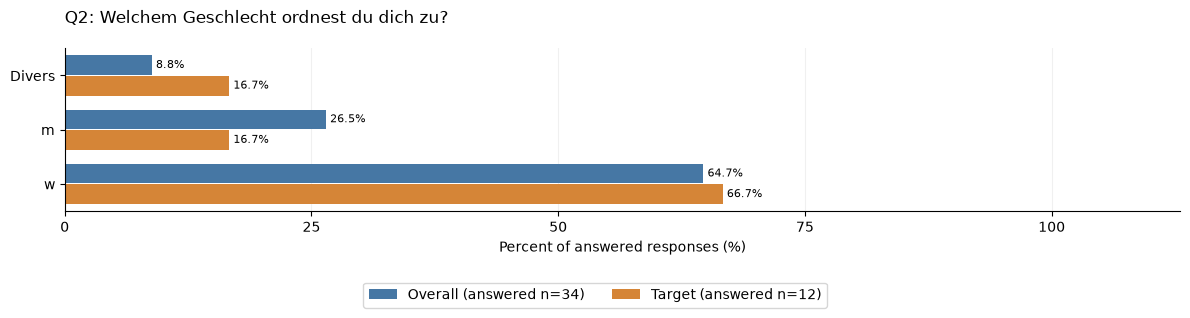

In [5]:
report(2)


### Q3 — In welchem Bundesland arbeitest du?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Baden-Württemberg""",2,5.88,0,0.00,-5.88
"""Bayern""",1,2.94,0,0.00,-2.94
"""Berlin""",13,38.24,7,58.33,20.10
"""Brandenburg""",8,23.53,2,16.67,-6.86
"""Hamburg""",5,14.71,1,8.33,-6.37
"""Hessen""",1,2.94,0,0.00,-2.94
"""Mecklenburg-Vorpommern""",1,2.94,0,0.00,-2.94
"""Nordrhein-Westfalen""",1,2.94,1,8.33,5.39
"""Sachsen""",2,5.88,1,8.33,2.45


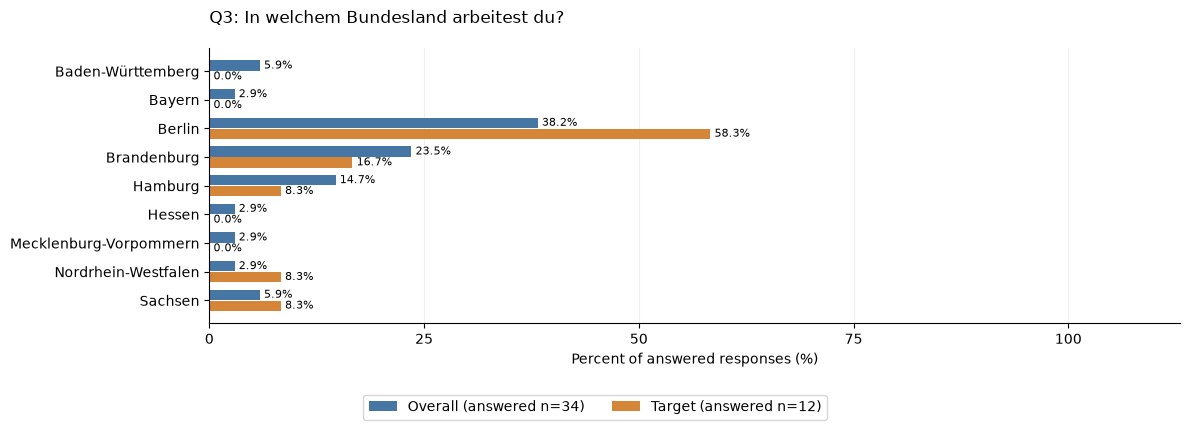

In [6]:
report(3)


### Q4 — Wie viele Berufsjahre arbeitest du bereits?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""5 - 20 Jahre""",18,52.94,5,41.67,-11.27
"""mehr als 20 Jahre""",10,29.41,5,41.67,12.25
"""weniger als 5 Jahre""",6,17.65,2,16.67,-0.98


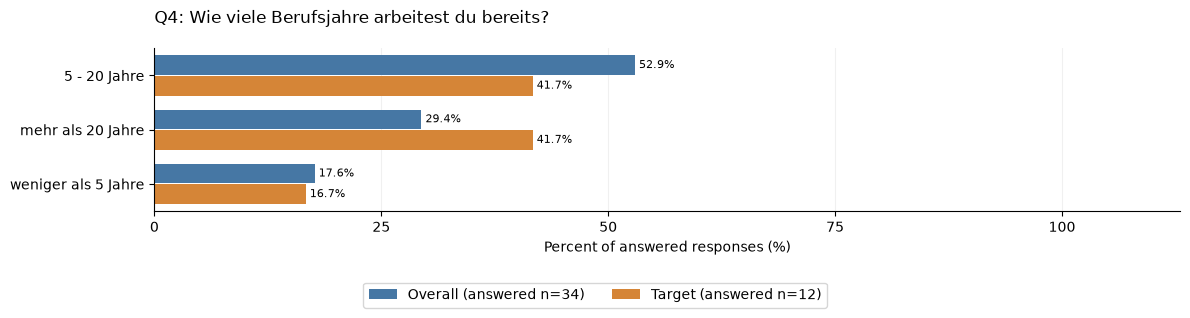

In [7]:
report(4)


### Q5 — Zu welcher Gruppe ordnest du dich zu?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Andere""",5,14.71,1,8.33,-6.37
"""Coaches / Referenten""",2,5.88,1,8.33,2.45
"""Freischaffende mit pädagogischer Ausbildung""",5,14.71,2,16.67,1.96
"""Freischaffende ohne pädagogische Ausbildung""",4,11.76,1,8.33,-3.43
"""Lehrkräfte""",1,2.94,1,8.33,5.39
"""Sozialpädagogen""",17,50.00,6,50.00,0.00


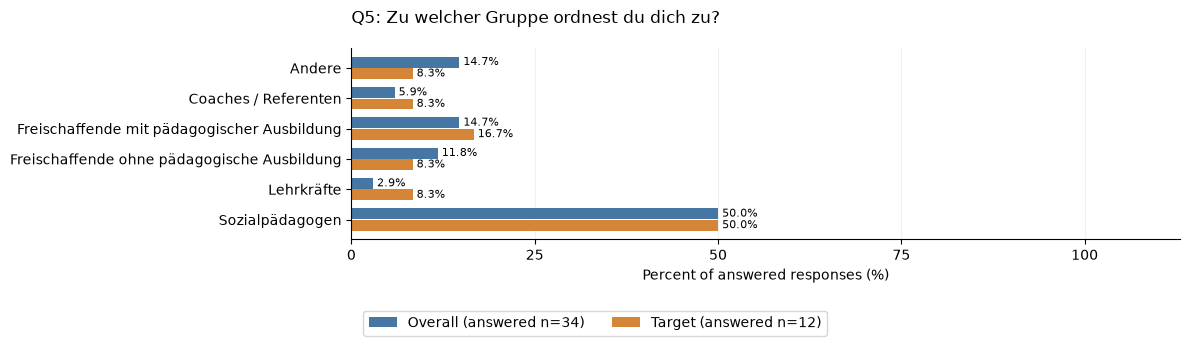

In [8]:
report(5)


## Resources and investment

Budget and time brackets are reported verbatim. Funding-program answers may be conditional on earlier responses; consult the answered denominators.


### Q6 — Welche finanziellen Mittel stehen dir aktuell für Fort- und Weiterbildungen zur Verfügung?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Keine""",7,20.59,2,16.67,-3.92
"""Arbeitgeber""",14,41.18,5,41.67,0.49
"""Projekt""",1,2.94,0,0.00,-2.94
"""Bildungsgutscheine""",0,0.00,0,0.00,0.00
"""Förderprogramme""",1,2.94,1,8.33,5.39
"""Persönliche Investments""",16,47.06,5,41.67,-5.39


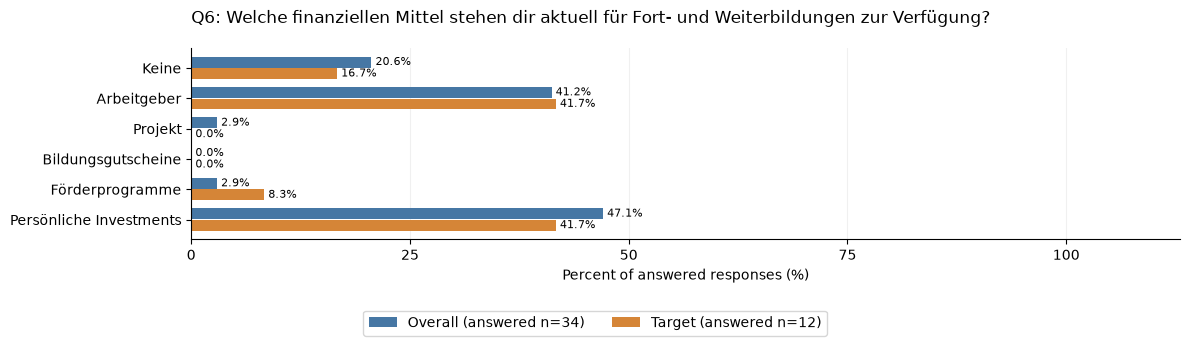

In [9]:
report(6)


### Q7 — Wie hoch waren diese finanziellen Mittel in den letzten 12 Monaten?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,27,7
"""Target""",12,10,2


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""1.000 - 5.000 € Jahr""",10,37.04,4,40.00,2.96
"""weniger als 1.000 € / Jahr""",17,62.96,6,60.00,-2.96


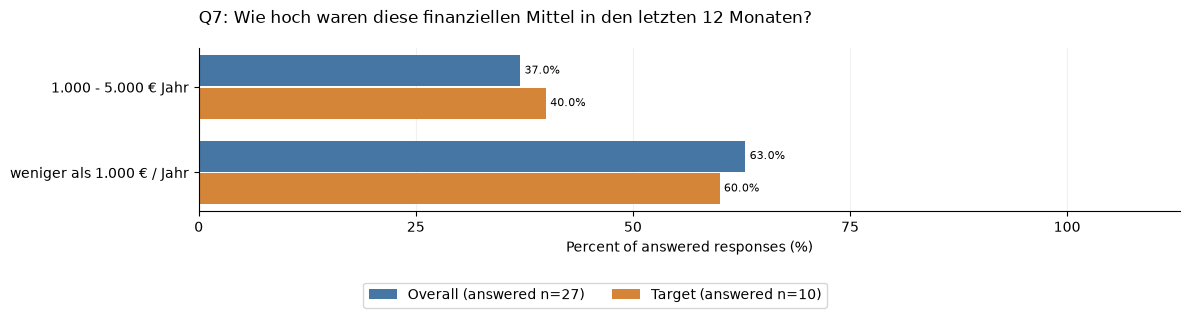

In [10]:
report(7)


### Q8 — Welche Förderprogramme?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,1,33
"""Target""",12,1,11


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Bildungsurlaub""",0,0.00,0,0.00,0.00
"""Bildungsgutschein / Bildungsscheck""",0,0.00,0,0.00,0.00
"""KOMPASS""",1,100.00,1,100.00,0.00
"""Projektförderung""",0,0.00,0,0.00,0.00
"""Andere...""",0,0.00,0,0.00,0.00


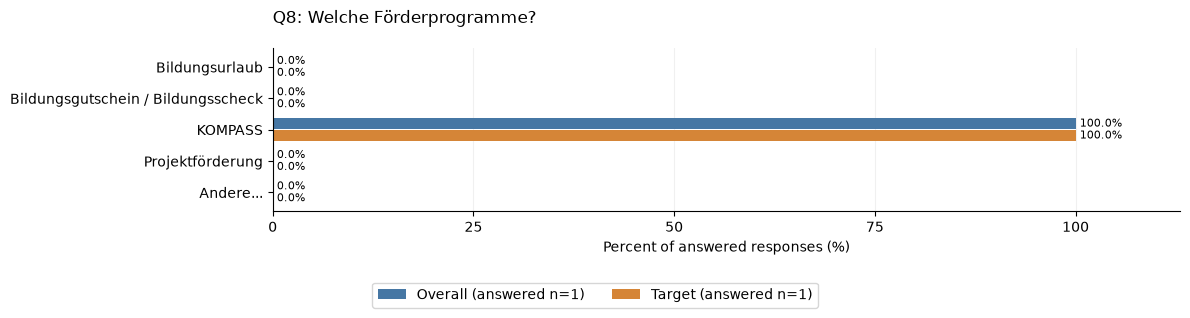

In [11]:
report(8)


### Q10 — Wie viel Zeit hast du die letzten 12 Monate in Fort- und Weiterbildung investiert?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""1 – 8 h""",8,23.53,2,16.67,-6.86
"""8 – 40 h""",13,38.24,3,25.00,-13.24
"""mehr als 40 h""",9,26.47,5,41.67,15.20
"""weniger als 1 h""",4,11.76,2,16.67,4.90


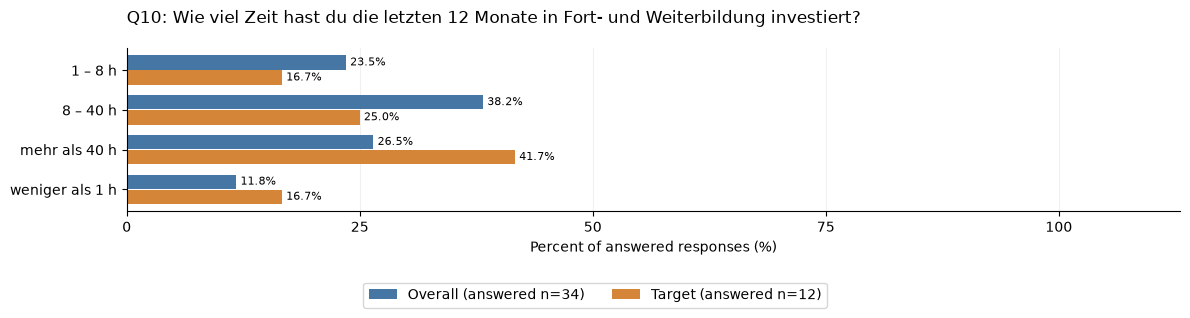

In [ ]:
report(10)

# comparison to Germany 2022:
# weniger als 1 h:  44%
# 1 - 8 h:          18%
# 8 - 40 h:         23%
# > 40 h:           16%


### Q11 — Möchtest du für 2027 weniger, mehr oder gleich viel Zeit investieren?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Gleich""",15,44.12,4,33.33,-10.78
"""Mehr""",15,44.12,6,50.00,5.88
"""Weniger""",4,11.76,2,16.67,4.90


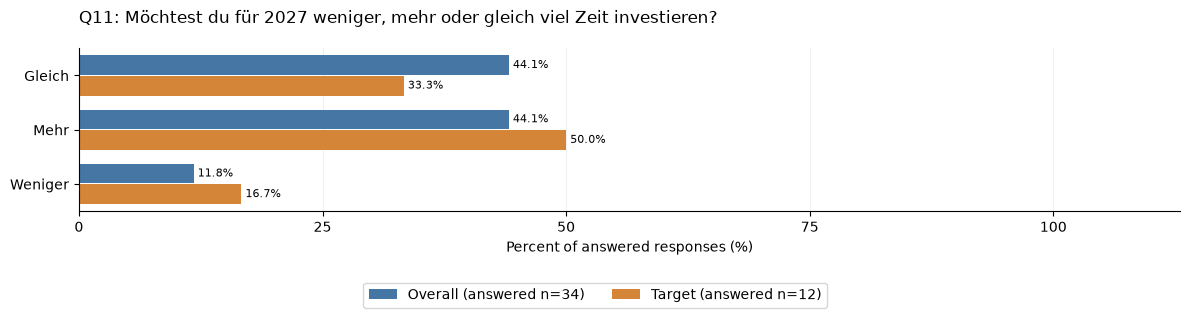

In [13]:
report(11)


## Decisions, criteria and expected benefits

Multiple options may be selected. A zero count means no selection among respondents who answered the question, not proof that an option is unimportant.


### Q13 — Hast du die Entscheidung für die Teilnahme selbst getroffen oder war jemand anderes bei der Entscheidung beteiligt?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Selbst getroffen""",30,88.24,11,91.67,3.43
"""Freigabe von Arbeitgeber für Zeit""",4,11.76,1,8.33,-3.43
"""Freigabe von Arbeitgeber für Finanzierung""",0,0.00,0,0.00,0.00
"""Freigabe von Arbeitgeber für Zeit & Finanzierung""",5,14.71,1,8.33,-6.37
"""Vorschlag/Anweisung von Arbeitgeber""",2,5.88,0,0.00,-5.88
"""Vorschlag von Kolleg:innen""",0,0.00,0,0.00,0.00


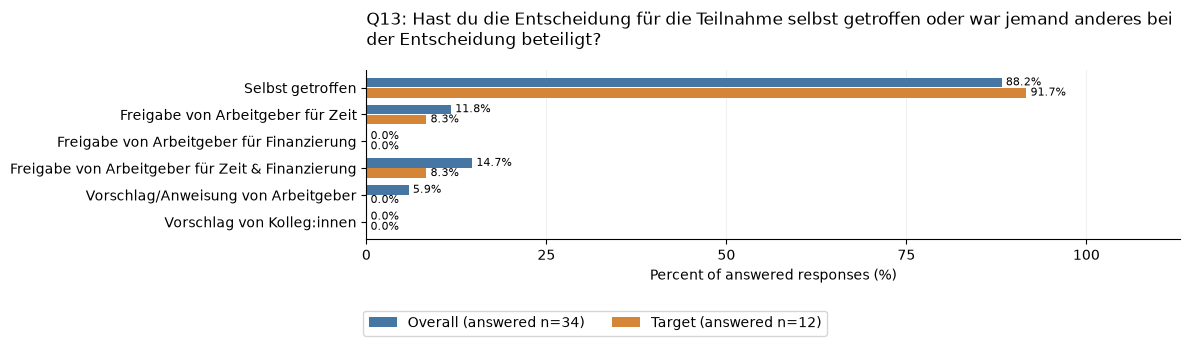

In [14]:
report(13)


### Q14 — Was waren deine Kriterien bei der Auswahl?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Passt zu meiner täglichen Arbeit""",28,82.35,10,83.33,0.98
"""Relevanz für die Arbeit mit Jugendlichen""",19,55.88,9,75.00,19.12
"""Schwerpunkt auf Stärken und Identitätsfindung""",6,17.65,4,33.33,15.69
"""Viele praktische Übungen und direkt nutzbare Methoden""",16,47.06,8,66.67,19.61
"""Fachliche Kompetenz der durchführenden Person""",15,44.12,6,50.00,5.88
"""Empfehlung""",2,5.88,1,8.33,2.45
"""Dauer und zeitlicher Aufwand""",9,26.47,3,25.00,-1.47
"""Online""",10,29.41,5,41.67,12.25
"""Präsenzformat""",14,41.18,7,58.33,17.16


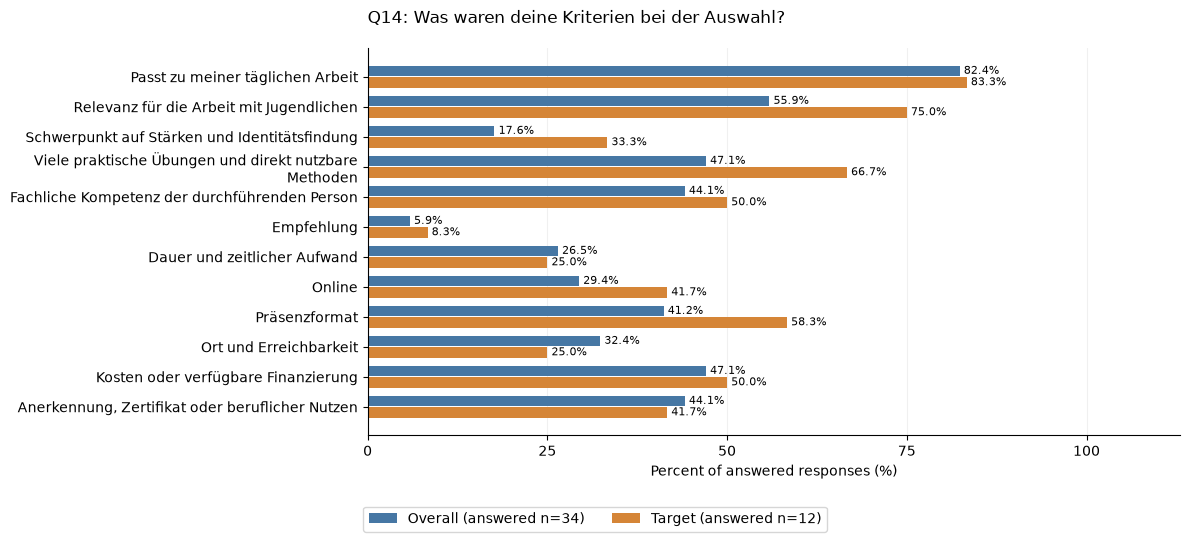

In [15]:
report(14)


### Q15 — Warum hast du dich für diese Fort- oder Weiterbildung entschieden?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Das Thema ist für meine aktuelle Arbeit relevant""",27,79.41,9,75.00,-4.41
"""Ich wollte Jugendliche besser unterstützen können""",11,32.35,8,66.67,34.31
"""Ich wollte mehr über Stärken und Identitätsfindung erfahren""",4,11.76,3,25.00,13.24
"""Ich wollte neue Methoden und Materialien kennenlernen""",20,58.82,8,66.67,7.84
"""Ich habe in meiner Arbeit einen konkreten Lernbedarf bemerkt""",6,17.65,3,25.00,7.35
"""Die Fortbildung wurde mir empfohlen""",1,2.94,0,0.00,-2.94
"""Die Teilnahme war für meine Rolle oder Arbeit erwartet""",5,14.71,2,16.67,1.96
"""Ich wollte mich beruflich weiterentwickeln""",20,58.82,9,75.00,16.18
"""Das Thema hat mich persönlich interessiert""",18,52.94,9,75.00,22.06


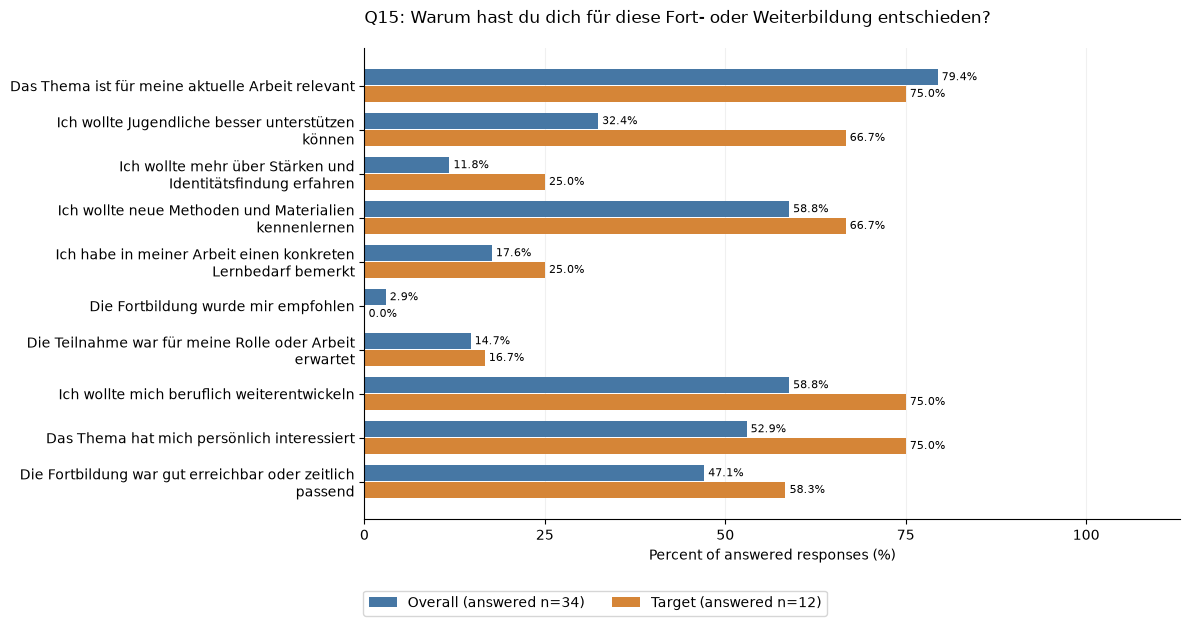

In [16]:
report(15)


### Q16 — Welchen Nutzen hast du dir erhofft?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Mehr Wissen zum Thema""",23,67.65,10,83.33,15.69
"""Konkrete Methoden für Gespräche mit Jugendlichen""",14,41.18,9,75.00,33.82
"""Mehr Sicherheit bei sensiblen oder schwierigen Gesprächen""",14,41.18,6,50.00,8.82
"""Jugendliche besser in ihren Stärken erkennen und fördern""",10,29.41,7,58.33,28.92
"""Besser auf unterschiedliche Lebenswelten eingehen können""",13,38.24,6,50.00,11.76
"""Ideen für die direkte Anwendung im Arbeitsalltag""",17,50.00,9,75.00,25.00
"""Austausch und neue Perspektiven von anderen Fachkräften""",17,50.00,6,50.00,0.00
"""Mehr Klarheit darüber, wie ich Jugendliche begleiten kann""",7,20.59,5,41.67,21.08
"""Einen Nachweis oder eine berufliche Qualifikation erhalten""",13,38.24,6,50.00,11.76


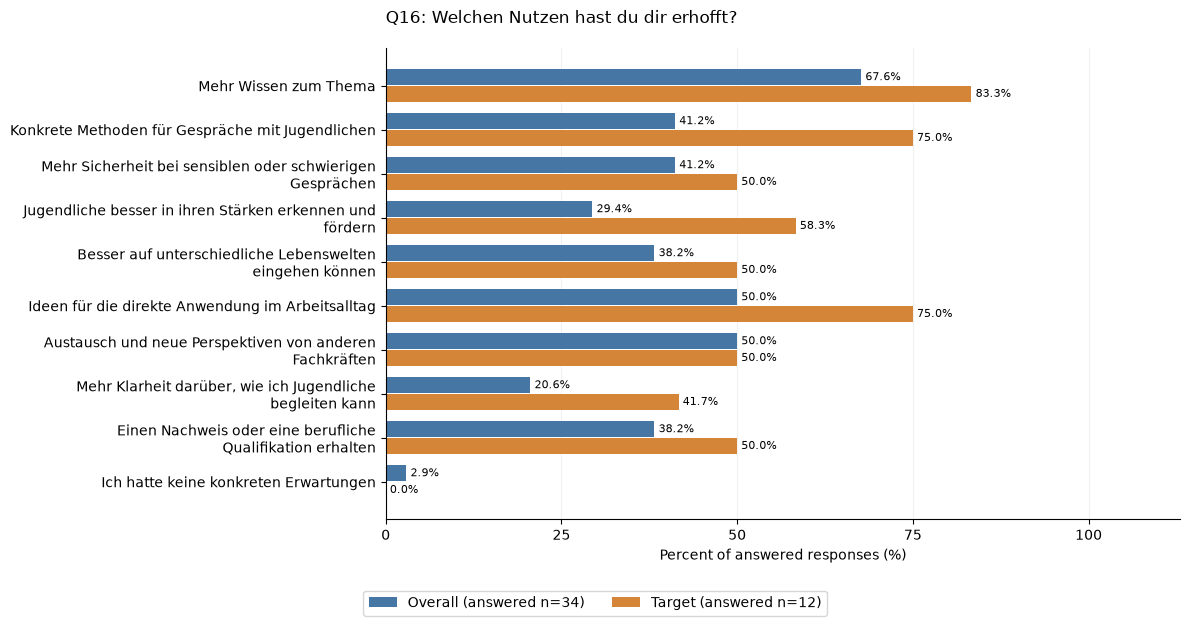

In [17]:
report(16)


## Discovery and barriers

Interpret challenges and participation barriers as reported selections, not causal explanations.


### Q17 — Wo hast du nach Fort- und Weiterbildungen gesucht?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,33,1
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Internetsuche""",21,63.64,10,83.33,19.70
"""Erfahrungsberichte von Kolleg:innen""",10,30.30,4,33.33,3.03
"""Staatliche Angebote""",4,12.12,1,8.33,-3.79
"""Sozialämter""",0,0.00,0,0.00,0.00
"""Arbeitsagentur""",0,0.00,0,0.00,0.00
"""Andere...""",10,30.30,1,8.33,-21.97


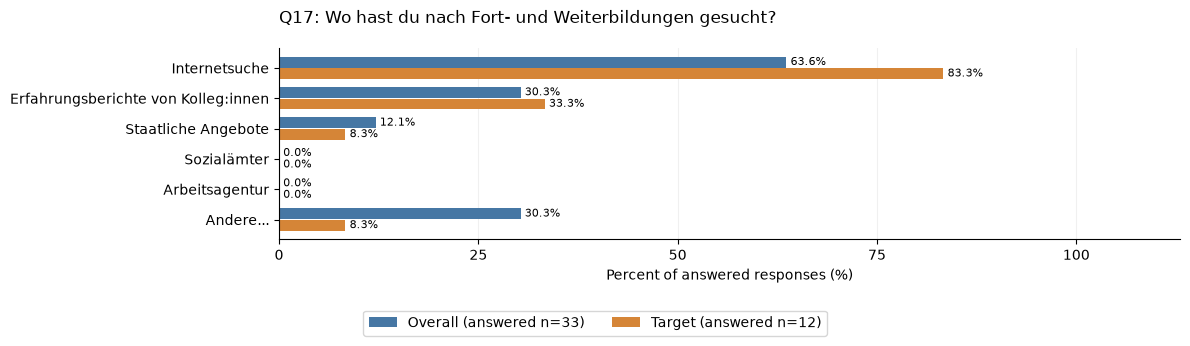

In [18]:
report(17)


### Q19 — Welche Herausforderungen hattest du bei der Auswahl, Freigabe oder Teilnahme an der Fort- oder Weiterbildung?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,33,1
"""Target""",12,11,1


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Passende Fortbildungen waren schwer zu finden""",6,18.18,5,45.45,27.27
"""Es war unklar, welche Fortbildung zu meinem Bedarf passt""",1,3.03,1,9.09,6.06
"""Die Freigabe durch meinen Arbeitgeber war schwierig""",4,12.12,0,0.00,-12.12
"""Die Kosten konnten nicht oder nur teilweise übernommen werden""",10,30.30,4,36.36,6.06
"""Es fehlte Zeit neben der regulären Arbeit""",17,51.52,7,63.64,12.12
"""Vertretung oder Personalmangel erschwerte die Teilnahme""",7,21.21,3,27.27,6.06
"""Termin oder Dauer passten nicht""",4,12.12,1,9.09,-3.03
"""Anreise oder Veranstaltungsort waren schwierig""",4,12.12,2,18.18,6.06
"""Das Format passte nicht zu meinen Lernbedürfnissen""",0,0.00,0,0.00,0.00


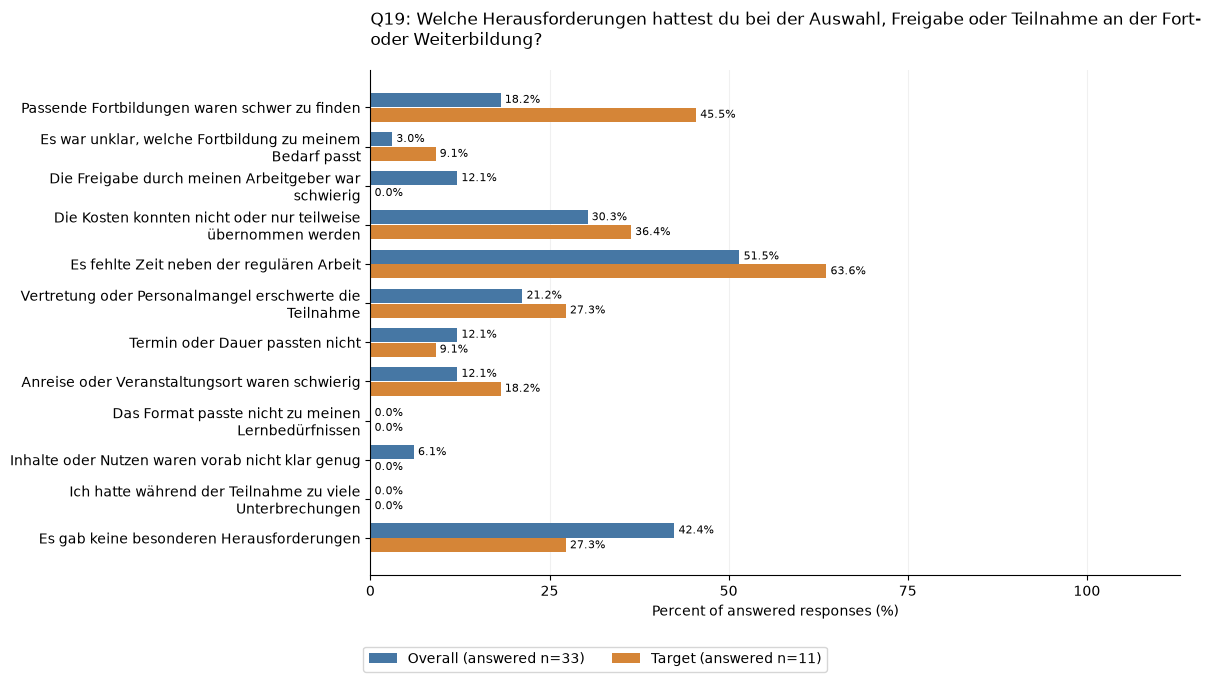

In [19]:
report(19)


### Q20 — Was hat dich davon abgehalten, an mehr Fort- oder Weiterbildungen teilzunehmen?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,33,1
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Zu wenig Zeit""",19,57.58,8,66.67,9.09
"""Zu wenig finanzielle Mittel""",13,39.39,4,33.33,-6.06
"""Fehlende Freigabe von Arbeitgeber""",3,9.09,1,8.33,-0.76
"""Persönliche Zeitplanung""",6,18.18,2,16.67,-1.52
"""Fehlende Angebote""",8,24.24,3,25.00,0.76
"""Logistische Gründe""",2,6.06,0,0.00,-6.06
"""Andere...""",4,12.12,3,25.00,12.88


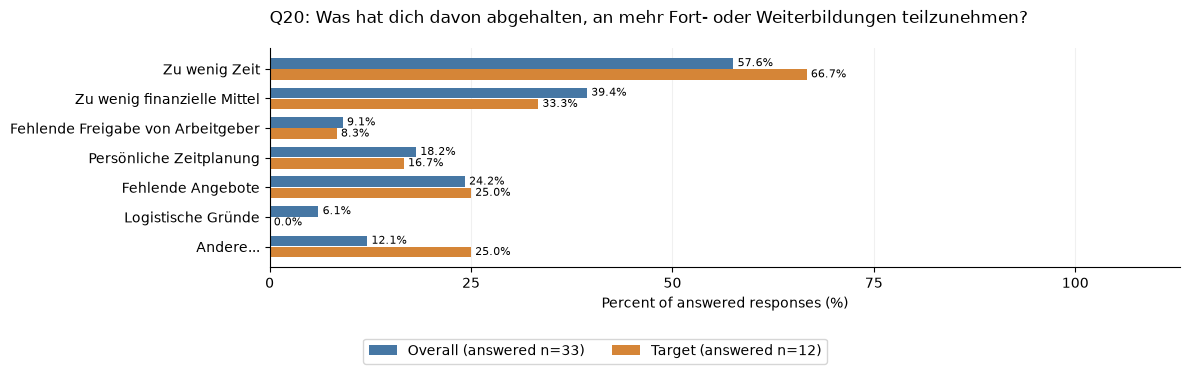

In [20]:
report(20)


## Format attractiveness and positive experiences

Format ratings are ordinal (higher is better). Q24 reports selected positive features without displaying the free-text training descriptions.


### Q22 — Welches Format unabhängig vom Thema der Fort- oder Weiterbildung ist für dich am attraktivsten?

**Digital - 1 Stunde**

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""1""",7,20.59,1,8.33,-12.25
"""2""",11,32.35,6,50.00,17.65
"""3""",5,14.71,1,8.33,-6.37
"""4""",11,32.35,4,33.33,0.98


Group,Q1,Median_lower,Q3
str,f64,f64,f64
"""Overall""",2.00,2.00,4.00
"""Target""",2.00,2.00,4.00


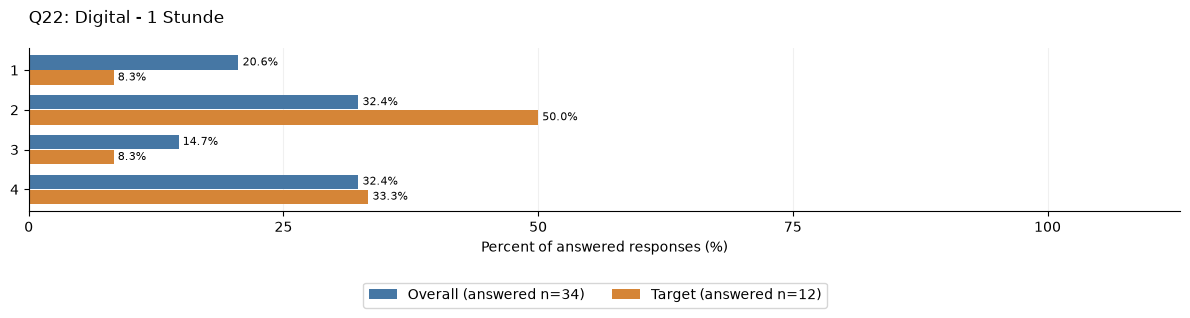

**Vor Ort - 8 Stunden**

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""1""",3,8.82,1,8.33,-0.49
"""2""",5,14.71,1,8.33,-6.37
"""3""",16,47.06,6,50.00,2.94
"""4""",10,29.41,4,33.33,3.92


Group,Q1,Median_lower,Q3
str,f64,f64,f64
"""Overall""",3.00,3.00,4.00
"""Target""",3.00,3.00,4.00


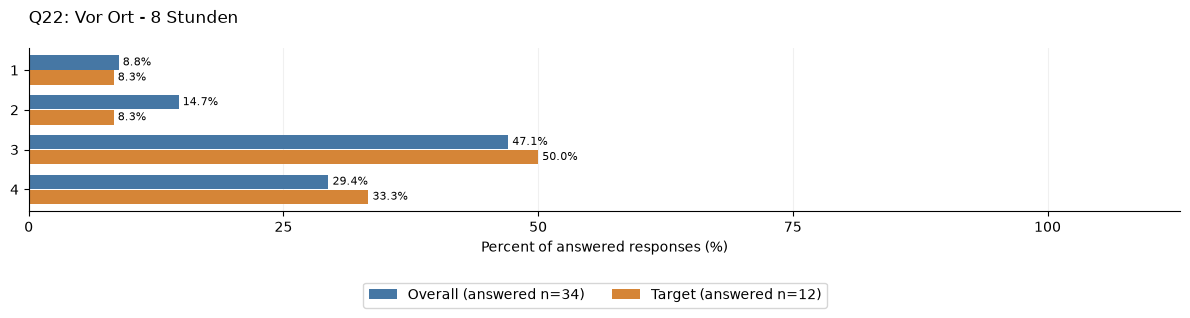

**Vor Ort – 4x 2 Stunden**

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""1""",11,32.35,3,25.00,-7.35
"""2""",13,38.24,6,50.00,11.76
"""3""",8,23.53,3,25.00,1.47
"""4""",2,5.88,0,0.00,-5.88


Group,Q1,Median_lower,Q3
str,f64,f64,f64
"""Overall""",1.00,2.00,3.00
"""Target""",1.00,2.00,2.00


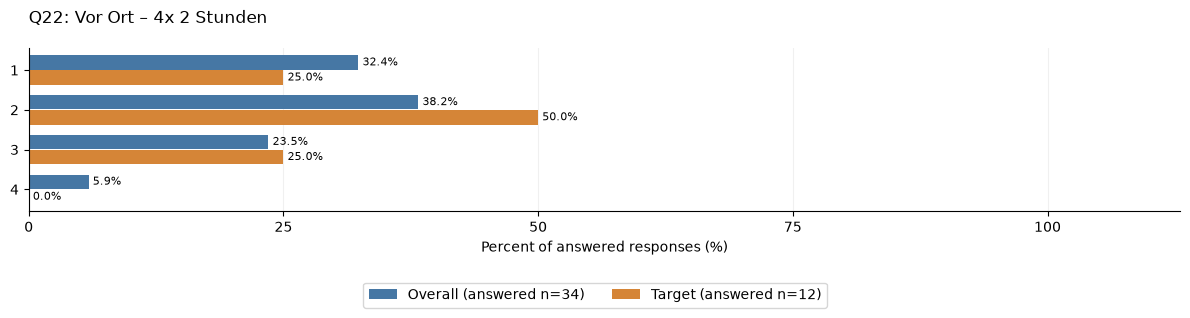

**Vor Ort – 4 Stunden plus Digital – 4x 2 Stunden**

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""1""",7,20.59,2,16.67,-3.92
"""2""",9,26.47,4,33.33,6.86
"""3""",13,38.24,5,41.67,3.43
"""4""",5,14.71,1,8.33,-6.37


Group,Q1,Median_lower,Q3
str,f64,f64,f64
"""Overall""",2.00,3.00,3.00
"""Target""",2.00,2.00,3.00


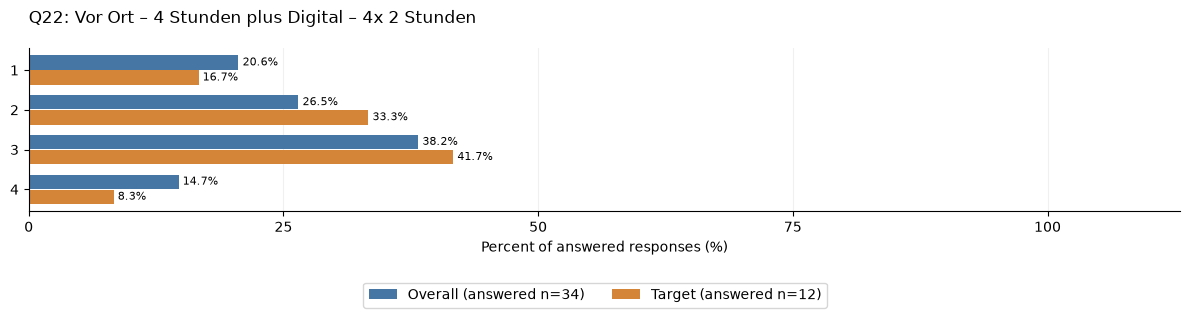

In [21]:
report(22)


### Q24 — Was hat dir an dieser Fort- oder Weiterbildung besonders gefallen?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,25,9
"""Target""",12,8,4


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Die Inhalte waren relevant für meine Arbeit""",22,88.00,8,100.00,12.00
"""Die Methoden waren praktisch und direkt anwendbar""",21,84.00,7,87.50,3.50
"""Die Beispiele passten zur Arbeit mit Jugendlichen""",14,56.00,6,75.00,19.00
"""Die Fortbildung hat mein Wissen erweitert""",21,84.00,8,100.00,16.00
"""Die Übungen und der Austausch waren hilfreich""",21,84.00,8,100.00,16.00
"""Die Leitung der Fortbildung war fachlich überzeugend""",19,76.00,8,100.00,24.00
"""Es gab Raum für Fragen und eigene Erfahrungen""",20,80.00,8,100.00,20.00
"""Ich habe neue Perspektiven kennengelernt""",19,76.00,8,100.00,24.00
"""Die Atmosphäre war offen und wertschätzend""",21,84.00,8,100.00,16.00


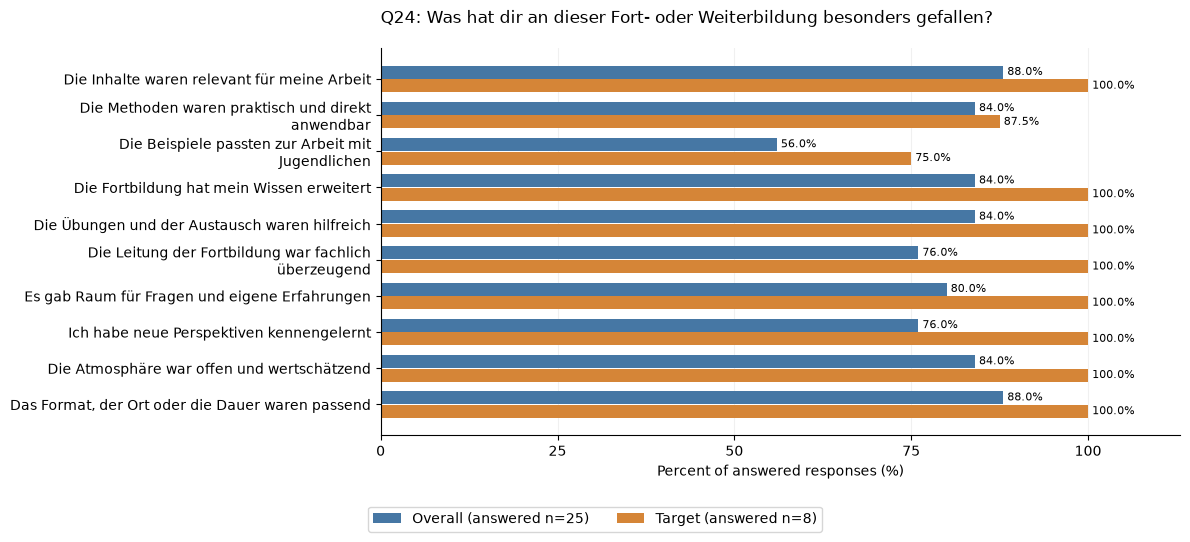

In [22]:
report(24)


## Interest and support needs

Q25 is shown explicitly as the target-selection variable. Q26 and Q27 describe support needs and prospective time investment within this selected sample.


### Q25 — Wie hoch ist dein Interesse für das Thema Stärken- und Identitätsfindung für Jugendliche?

**Selection effect:** Target is defined by rating 4 on this question. Its distribution is a rule check, not evidence of an independently observed preference difference.

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,34,0
"""Target""",12,12,0


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""1""",3,8.82,0,0.00,-8.82
"""2""",10,29.41,0,0.00,-29.41
"""3""",9,26.47,0,0.00,-26.47
"""4""",12,35.29,12,100.00,64.71


Group,Q1,Median_lower,Q3
str,f64,f64,f64
"""Overall""",2.00,3.00,4.00
"""Target""",4.00,4.00,4.00


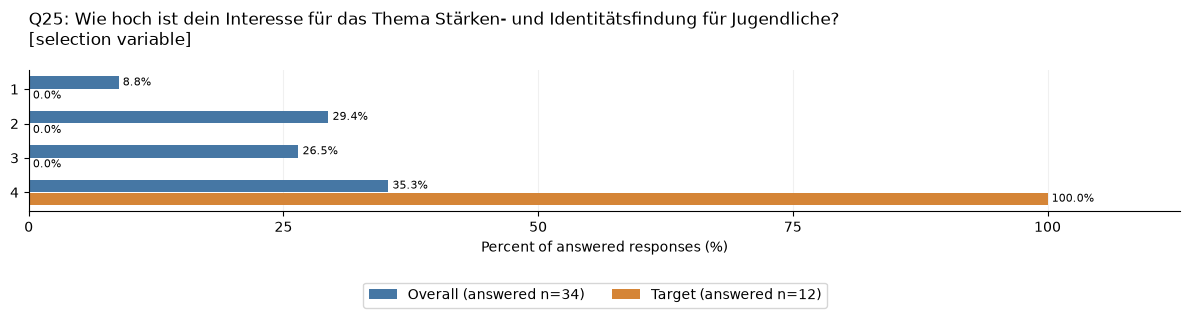

In [23]:
report(25)


### Q26 — Was fehlt dir aktuell bei der Arbeit mit Jugendlichen, um das Thema Stärken- und Identitätsfindung zu besprechen?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,31,3
"""Target""",12,11,1


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""Mehr Wissen über Stärken und Identitätsentwicklung""",6,19.35,5,45.45,26.10
"""Konkrete Gesprächsleitfäden oder Fragen""",7,22.58,5,45.45,22.87
"""Übungen und Materialien für die praktische Arbeit""",12,38.71,7,63.64,24.93
"""Mehr Sicherheit, das Thema anzusprechen""",4,12.90,3,27.27,14.37
"""Unterstützung beim Umgang mit schwierigen Reaktionen oder sensiblen Themen""",12,38.71,7,63.64,24.93
"""Mehr Zeit für vertiefte Gespräche""",13,41.94,9,81.82,39.88
"""Ein geeigneter, geschützter Raum für Gespräche""",7,22.58,3,27.27,4.69
"""Unterstützung durch Kolleginnen, Kollegen oder Leitung""",1,3.23,1,9.09,5.87
"""Materialien, die verschiedene Sprachen und Lebenswelten berücksichtigen""",14,45.16,6,54.55,9.38


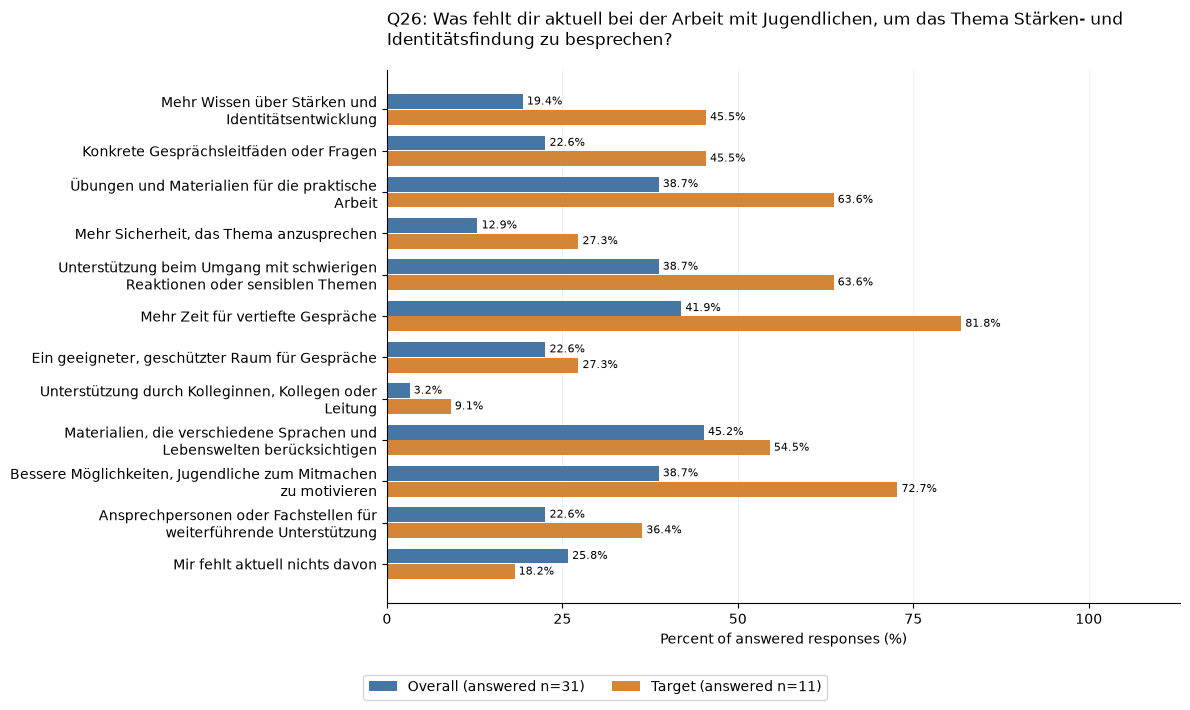

In [24]:
report(26)


### Q27 — Wie viel Zeit würdest du für eine Fort- oder Weiterbildung zu diesem Thema investieren?

Group,Eligible,Answered,Missing
str,u32,u32,u32
"""Overall""",34,31,3
"""Target""",12,11,1


Response,Overall_n,Overall_%,Target_n,Target_%,Diff_pp
str,u32,f64,u32,f64,f64
"""1 - 8 h""",23,74.19,6,54.55,-19.65
"""mehr als 8 h""",5,16.13,5,45.45,29.33
"""weniger als 1 h""",3,9.68,0,0.00,-9.68


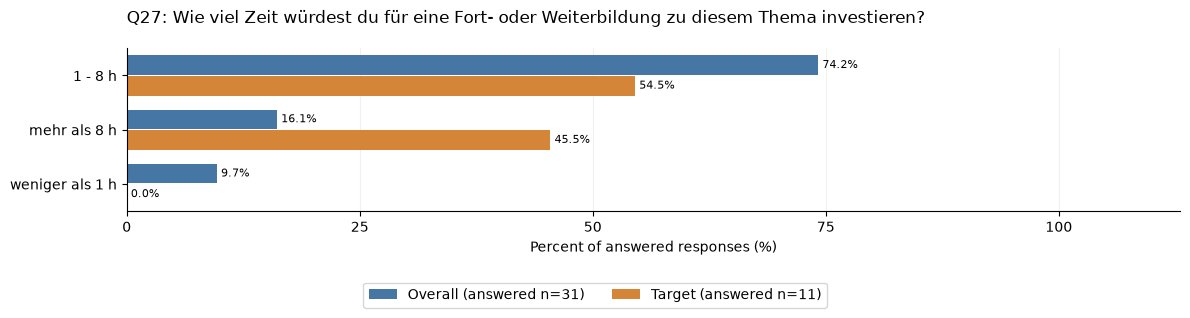

In [25]:
report(27)


## Interpretation and limitations
Use each table's answered and missing counts alongside its percentages. A positive `Diff_pp` means a larger conditional share in Target than Overall; a negative value means a smaller share. Because Overall includes Target, these are overlapping descriptive summaries, not independent-group comparisons. The Q25 difference is imposed by selection and must not be presented as a new finding.

- **Small, selected sample:** a few respondents can change percentages substantially. Neither cohort establishes population prevalence or representativeness.
- **Shared respondents:** Target is contained in Overall. No independent-group tests, p-values, confidence intervals or causal claims are warranted here.
- **Conditional denominators:** each question/item can describe a different responding subset. Missingness may reflect nonresponse or routing; the CSV alone does not distinguish them. Compare the missingness audit before interpreting contrasts.
- **Multiple responses:** checkbox percentages may sum to more than 100%; all-empty checkbox questions are excluded from their denominator. Never-selected schema options remain visible.
- **Ordinal measurement:** rating codes and budget/time brackets do not justify interval-scale averages. Lower-category medians and quartiles follow the explicitly stated convention.
- **Export vocabulary:** single-choice tables include every nonempty category observed in the supplied source export, even if its eligible count becomes zero. The export does not establish additional never-observed single-choice options. Unexpected categories or encodings require explicit review.
- **Privacy:** outputs are aggregate only; no respondent-level rows, IDs, emails, or free-text answers are rendered. Small aggregate cells can still be sensitive and should be reviewed before public sharing.
